# Comparative Sentiment Analysis: Linear SVM vs. Multinomial Naïve Bayes
**Course:** CSE 303 – Machine Learning | **Assignment:** CLA3 Case Study (Topic T7)  
**Dataset:** Amazon Review Polarity (12,000 Balanced Customer Reviews: 8k Train / 2k Val / 2k Test)  
**Implementation:** Python 3, Scikit-Learn, Pandas, NumPy, Matplotlib, Seaborn

---
### Project Objectives:
1. Construct an end-to-end NLP sentiment classification pipeline with negation-preserving text cleaning.
2. Extract sublinear TF-IDF unigram and bigram features strictly on training data (no leakage).
3. Train and hyperparameter-tune **Linear Support Vector Machine (Linear SVM)** and **Multinomial Naïve Bayes (MNB)**.
4. Perform empirical threshold optimization on a held-out validation split.
5. Evaluate both models on an untouched test set across Accuracy, Precision, Recall, F1, ROC-AUC, and latency.
6. Provide an interactive live sentiment prediction interface for user-provided reviews.


## 1. Setup & Dependencies

In [1]:
# In Google Colab, uncomment and run:
# !pip install -q pandas numpy scikit-learn matplotlib seaborn datasets

import os
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Environment initialized successfully.")


Environment initialized successfully.


## 2. Dataset Loading & Partitioning
We use a stratified, balanced subset of **12,000 Amazon product reviews**:
* **Training set:** 8,000 reviews (4,000 negative, 4,000 positive)
* **Validation set:** 2,000 reviews (1,000 negative, 1,000 positive)
* **Test set:** 2,000 reviews (1,000 negative, 1,000 positive)


In [2]:
# Load partitioned dataset
train_df = pd.read_csv("Dataset/train_sample.csv")
val_df = pd.read_csv("Dataset/val_sample.csv")
test_df = pd.read_csv("Dataset/test_sample.csv")

print(f"Train samples: {len(train_df):,} | Class balance: {dict(train_df['label'].value_counts())}")
print(f"Val samples:   {len(val_df):,} | Class balance: {dict(val_df['label'].value_counts())}")
print(f"Test samples:  {len(test_df):,} | Class balance: {dict(test_df['label'].value_counts())}")
train_df.head(3)


Train samples: 8,000 | Class balance: {0: np.int64(4000), 1: np.int64(4000)}
Val samples:   2,000 | Class balance: {1: np.int64(1000), 0: np.int64(1000)}
Test samples:  2,000 | Class balance: {1: np.int64(1000), 0: np.int64(1000)}


,text,label
0,Terrible adaptation of a CLAMP classic. The No...,0
1,Fell apart after one season. This canner devel...,0
2,Footloose. Never got to watch it since I was s...,0


## 3. Exploratory Data Analysis (EDA)

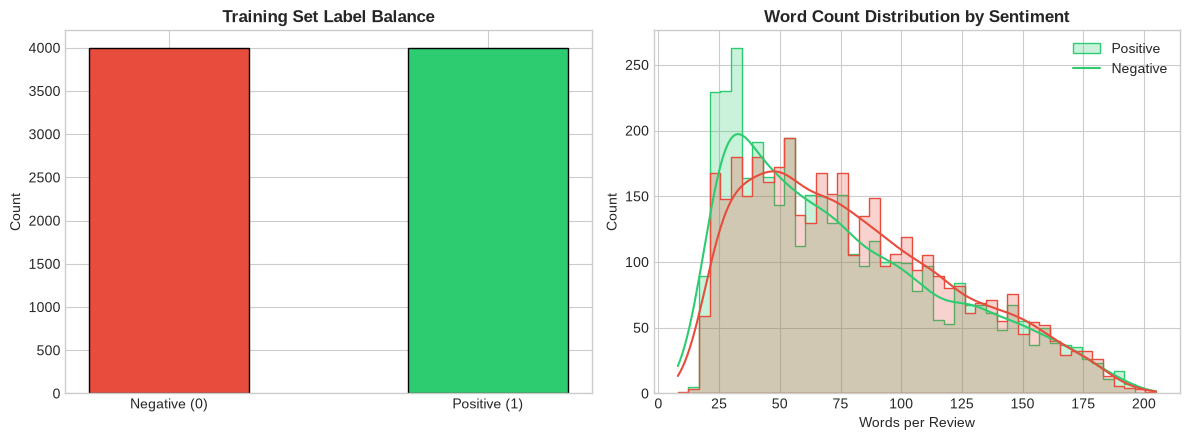

Average review length: 78.4 words (Median: 70)


In [3]:
# Class distribution and review length analysis
train_df['word_count'] = train_df['text'].apply(lambda t: len(str(t).split()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Class Distribution
counts = train_df['label'].value_counts().rename(index={0: 'Negative (0)', 1: 'Positive (1)'})
axes[0].bar(counts.index, counts.values, color=['#e74c3c', '#2ecc71'], edgecolor='black', width=0.5)
axes[0].set_title("Training Set Label Balance", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Count")

# 2. Word Count Distribution
sns.histplot(data=train_df, x='word_count', hue='label', palette={0: '#e74c3c', 1: '#2ecc71'},
             kde=True, bins=45, ax=axes[1], element='step', common_norm=False)
axes[1].set_title("Word Count Distribution by Sentiment", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Words per Review")
axes[1].legend(['Positive', 'Negative'])

plt.tight_layout()
plt.show()

print(f"Average review length: {train_df['word_count'].mean():.1f} words (Median: {train_df['word_count'].median():.0f})")


## 4. Text Preprocessing & TF-IDF Vectorization
Standard stopword removal often deletes negation words (`not`, `never`, `no`), inverting review polarity.  
Our preprocessor preserves negation tokens and expands common English contractions.


In [4]:
CONTRACTIONS = {
    r"won't": "will not", r"can't": "cannot", r"n't": " not",
    r"'re": " are", r"'s": " is", r"'d": " would",
    r"'ll": " will", r"'t": " not", r"'ve": " have", r"'m": " am"
}

def clean_text(text: str) -> str:
    text = str(text).lower()
    for pattern, replacement in CONTRACTIONS.items():
        text = re.sub(pattern, replacement, text)
    text = re.sub(r"<[^>]+>", " ", text)               # HTML tags
    text = re.sub(r"https?://\S+|www\.\S+", " ", text) # URLs
    text = re.sub(r"[^a-z\s]", " ", text)              # Non-alphabetic
    return re.sub(r"\s+", " ", text).strip()

# Apply cleaning
X_train_raw = train_df['text'].apply(clean_text).values
y_train = train_df['label'].values
X_val_raw = val_df['text'].apply(clean_text).values
y_val = val_df['label'].values
X_test_raw = test_df['text'].apply(clean_text).values
y_test = test_df['label'].values

# Fit TF-IDF strictly on training set (zero data leakage)
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=25000,
    min_df=2,
    sublinear_tf=True
)
X_train = vectorizer.fit_transform(X_train_raw)
X_val = vectorizer.transform(X_val_raw)
X_test = vectorizer.transform(X_test_raw)

print(f"Extracted TF-IDF Vocabulary: {len(vectorizer.vocabulary_):,} unigrams and bigrams.")


Extracted TF-IDF Vocabulary: 25,000 unigrams and bigrams.


## 5. Hyperparameter Tuning on Validation Set

In [5]:
# 1. Tuning Linear SVM (C penalty parameter)
c_values = [0.01, 0.1, 0.5, 1.0, 2.0, 5.0]
svm_val_scores = []
for c in c_values:
    m = LinearSVC(C=c, random_state=RANDOM_STATE, dual="auto")
    m.fit(X_train, y_train)
    score = f1_score(y_val, m.predict(X_val), average="macro")
    svm_val_scores.append(score)

best_c = c_values[np.argmax(svm_val_scores)]
print(f"Optimal SVM C: {best_c} (Validation Macro-F1: {max(svm_val_scores):.4f})")

# 2. Tuning Multinomial Naïve Bayes (alpha Laplace smoothing)
alpha_values = [0.01, 0.1, 0.5, 1.0, 2.0]
nb_val_scores = []
for a in alpha_values:
    m = MultinomialNB(alpha=a)
    m.fit(X_train, y_train)
    score = f1_score(y_val, m.predict(X_val), average="macro")
    nb_val_scores.append(score)

best_alpha = alpha_values[np.argmax(nb_val_scores)]
print(f"Optimal MNB alpha: {best_alpha} (Validation Macro-F1: {max(nb_val_scores):.4f})")


Optimal SVM C: 0.5 (Validation Macro-F1: 0.8980)
Optimal MNB alpha: 2.0 (Validation Macro-F1: 0.8679)


## 6. Model Training & Probability Calibration
To evaluate ROC-AUC and tune decision thresholds, we calibrate the Linear SVM using 5-fold Platt scaling (`CalibratedClassifierCV`).


In [6]:
# Train final Multinomial NB
t0 = time.perf_counter()
nb = MultinomialNB(alpha=best_alpha)
nb.fit(X_train, y_train)
nb_fit_time = (time.perf_counter() - t0) * 1000

# Train base Linear SVM
t0 = time.perf_counter()
base_svm = LinearSVC(C=best_c, random_state=RANDOM_STATE, dual="auto")
base_svm.fit(X_train, y_train)
svm_fit_time = (time.perf_counter() - t0) * 1000

# Fit Calibrated SVM for posterior probabilities
cal_svm = CalibratedClassifierCV(estimator=LinearSVC(C=best_c, random_state=RANDOM_STATE, dual="auto"), method="sigmoid", cv=5)
cal_svm.fit(X_train, y_train)

print(f"Training Time -> MNB: {nb_fit_time:.2f} ms | Linear SVM: {svm_fit_time:.2f} ms")


Training Time -> MNB: 3.52 ms | Linear SVM: 31.61 ms


## 7. Decision Threshold Optimization (Validation Sweep)

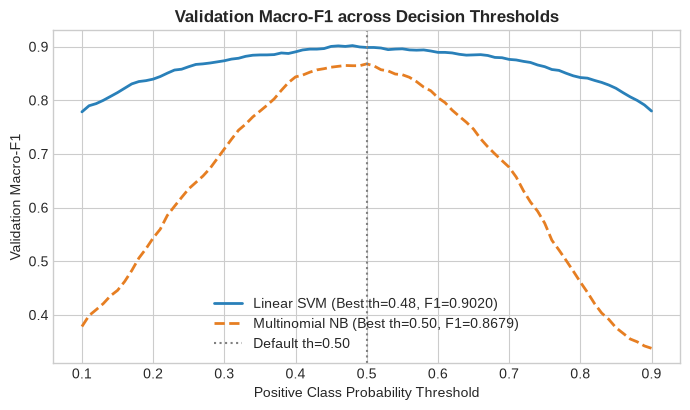

In [7]:
val_probs_nb = nb.predict_proba(X_val)[:, 1]
val_probs_svm = cal_svm.predict_proba(X_val)[:, 1]

thresholds = np.linspace(0.1, 0.9, 81)
nb_thresh_f1 = [f1_score(y_val, (val_probs_nb >= th).astype(int), average="macro") for th in thresholds]
svm_thresh_f1 = [f1_score(y_val, (val_probs_svm >= th).astype(int), average="macro") for th in thresholds]

best_nb_th = thresholds[np.argmax(nb_thresh_f1)]
best_svm_th = thresholds[np.argmax(svm_thresh_f1)]

plt.figure(figsize=(7, 4.2))
plt.plot(thresholds, svm_thresh_f1, label=f"Linear SVM (Best th={best_svm_th:.2f}, F1={max(svm_thresh_f1):.4f})", color="#2980b9", lw=2)
plt.plot(thresholds, nb_thresh_f1, label=f"Multinomial NB (Best th={best_nb_th:.2f}, F1={max(nb_thresh_f1):.4f})", color="#e67e22", lw=2, linestyle="--")
plt.axvline(0.5, color="gray", linestyle=":", label="Default th=0.50")
plt.title("Validation Macro-F1 across Decision Thresholds", fontsize=12, fontweight='bold')
plt.xlabel("Positive Class Probability Threshold")
plt.ylabel("Validation Macro-F1")
plt.legend()
plt.tight_layout()
plt.show()


## 8. Final Evaluation on Held-Out Test Set (2,000 Reviews)

In [8]:
test_probs_nb = nb.predict_proba(X_test)[:, 1]
test_probs_svm = cal_svm.predict_proba(X_test)[:, 1]

nb_preds = (test_probs_nb >= 0.5).astype(int)
svm_preds = (test_probs_svm >= 0.5).astype(int)

# Inference speed benchmark (ms per 1,000 samples)
t0 = time.perf_counter()
_ = nb.predict_proba(X_test)
nb_infer_time = ((time.perf_counter() - t0) / len(y_test)) * 1000 * 1000

t0 = time.perf_counter()
_ = cal_svm.predict_proba(X_test)
svm_infer_time = ((time.perf_counter() - t0) / len(y_test)) * 1000 * 1000

results_summary = pd.DataFrame({
    "Metric": [
        "Accuracy", "Precision (Positive)", "Recall (Positive)",
        "F1-Score (Positive)", "Macro-F1", "ROC-AUC",
        "Fit Time (ms)", "Inference Latency (ms/1k)"
    ],
    "Linear SVM": [
        f"{accuracy_score(y_test, svm_preds):.4f}",
        f"{precision_score(y_test, svm_preds):.4f}",
        f"{recall_score(y_test, svm_preds):.4f}",
        f"{f1_score(y_test, svm_preds):.4f}",
        f"{f1_score(y_test, svm_preds, average='macro'):.4f}",
        f"{roc_auc_score(y_test, test_probs_svm):.4f}",
        f"{svm_fit_time:.2f} ms",
        f"{svm_infer_time:.2f} ms"
    ],
    "Multinomial Naïve Bayes": [
        f"{accuracy_score(y_test, nb_preds):.4f}",
        f"{precision_score(y_test, nb_preds):.4f}",
        f"{recall_score(y_test, nb_preds):.4f}",
        f"{f1_score(y_test, nb_preds):.4f}",
        f"{f1_score(y_test, nb_preds, average='macro'):.4f}",
        f"{roc_auc_score(y_test, test_probs_nb):.4f}",
        f"{nb_fit_time:.2f} ms",
        f"{nb_infer_time:.2f} ms"
    ]
})

print(results_summary.to_string(index=False))


                   Metric Linear SVM Multinomial Naïve Bayes
                 Accuracy     0.8710                  0.8595
     Precision (Positive)     0.8695                  0.8780
        Recall (Positive)     0.8730                  0.8350
      F1-Score (Positive)     0.8713                  0.8560
                 Macro-F1     0.8710                  0.8594
                  ROC-AUC     0.9479                  0.9345
            Fit Time (ms)   31.61 ms                 3.52 ms
Inference Latency (ms/1k)    1.51 ms                 0.41 ms


## 9. Comparative Visualizations

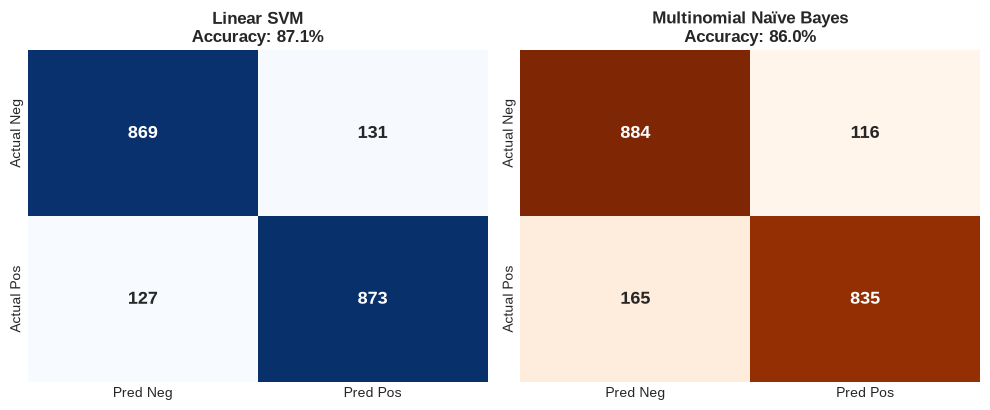

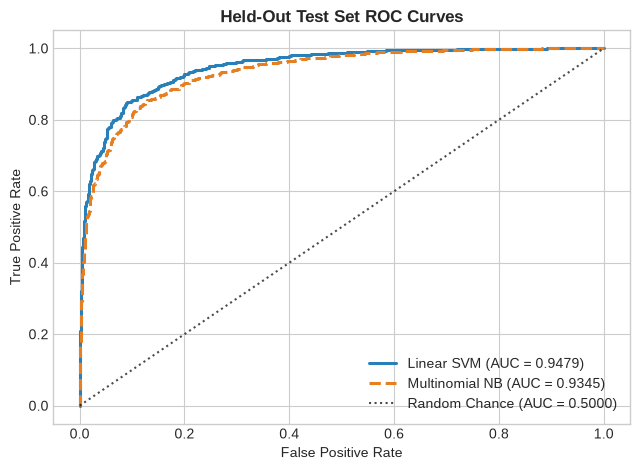

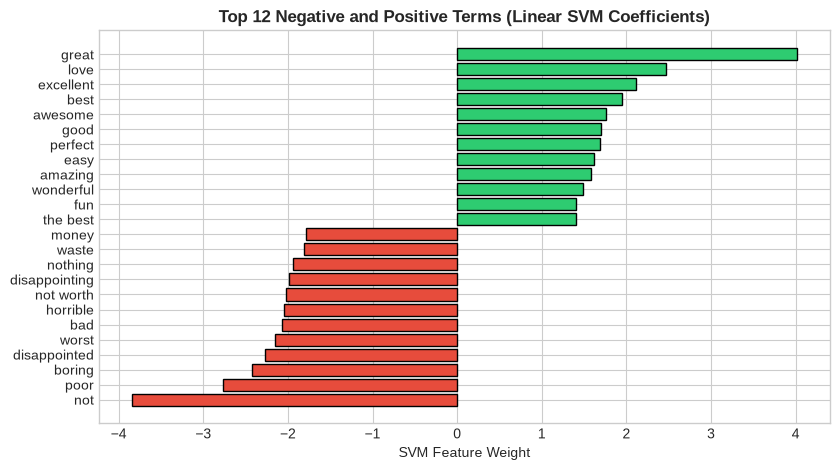

In [9]:
# 1. Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
cm_svm = confusion_matrix(y_test, svm_preds)
cm_nb = confusion_matrix(y_test, nb_preds)

for ax, cm, title, cmap in zip(axes, [cm_svm, cm_nb], ["Linear SVM", "Multinomial Naïve Bayes"], ["Blues", "Oranges"]):
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, cbar=False, ax=ax,
                xticklabels=["Pred Neg", "Pred Pos"], yticklabels=["Actual Neg", "Actual Pos"],
                annot_kws={"size": 13, "weight": "bold"})
    acc = (cm[0, 0] + cm[1, 1]) / len(y_test)
    ax.set_title(f"{title}\nAccuracy: {acc:.1%}", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. ROC Curves
fpr_svm, tpr_svm, _ = roc_curve(y_test, test_probs_svm)
fpr_nb, tpr_nb, _ = roc_curve(y_test, test_probs_nb)
auc_svm = roc_auc_score(y_test, test_probs_svm)
auc_nb = roc_auc_score(y_test, test_probs_nb)

plt.figure(figsize=(6.5, 4.8))
plt.plot(fpr_svm, tpr_svm, label=f"Linear SVM (AUC = {auc_svm:.4f})", color="#2980b9", lw=2.2)
plt.plot(fpr_nb, tpr_nb, label=f"Multinomial NB (AUC = {auc_nb:.4f})", color="#e67e22", lw=2.2, linestyle="--")
plt.plot([0, 1], [0, 1], "k:", label="Random Chance (AUC = 0.5000)", alpha=0.7)
plt.title("Held-Out Test Set ROC Curves", fontsize=12, fontweight='bold')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# 3. Model Interpretability: Top Feature Weights
feature_names = np.array(vectorizer.get_feature_names_out())
svm_coefs = base_svm.coef_.flatten()
top_pos_idx = np.argsort(svm_coefs)[-12:]
top_neg_idx = np.argsort(svm_coefs)[:12]

fig, ax = plt.subplots(figsize=(8.5, 4.8))
top_terms = list(feature_names[top_neg_idx]) + list(feature_names[top_pos_idx])
top_weights = list(svm_coefs[top_neg_idx]) + list(svm_coefs[top_pos_idx])
bar_colors = ["#e74c3c"] * 12 + ["#2ecc71"] * 12
ax.barh(top_terms, top_weights, color=bar_colors, edgecolor="black")
ax.set_title("Top 12 Negative and Positive Terms (Linear SVM Coefficients)", fontsize=12, fontweight='bold')
ax.set_xlabel("SVM Feature Weight")
plt.tight_layout()
plt.show()


## 10. Live Sentiment Prediction Function (Interactive)

In [10]:
def predict_sentiment(review_text: str):
    """Predict sentiment using both trained Linear SVM and Multinomial Naïve Bayes."""
    cleaned = clean_text(review_text)
    vec = vectorizer.transform([cleaned])
    
    t0 = time.perf_counter()
    p_svm = cal_svm.predict_proba(vec)[0][1]
    svm_time = (time.perf_counter() - t0) * 1000
    
    t0 = time.perf_counter()
    p_nb = nb.predict_proba(vec)[0][1]
    nb_time = (time.perf_counter() - t0) * 1000
    
    pred_svm = "POSITIVE" if p_svm >= best_svm_th else "NEGATIVE"
    pred_nb = "POSITIVE" if p_nb >= best_nb_th else "NEGATIVE"
    
    print(f"\nInput Review: \"{review_text}\"")
    print("-" * 65)
    print(f"  • Linear SVM   : {pred_svm:<8} | Confidence: {p_svm*100:5.1f}% | Latency: {svm_time:.2f} ms")
    print(f"  • Multi NB     : {pred_nb:<8} | Confidence: {p_nb*100:5.1f}% | Latency: {nb_time:.2f} ms")

# Test with diverse customer reviews
predict_sentiment("The headphone audio cuts out after 10 minutes. Complete waste of money!")
predict_sentiment("Incredible battery life and build quality. Exceeded all my expectations!")
predict_sentiment("Not bad for the price, works reasonably well for basic tasks.")
predict_sentiment("Don't buy this item, it broke on the first day.")



Input Review: "The headphone audio cuts out after 10 minutes. Complete waste of money!"
-----------------------------------------------------------------
  • Linear SVM   : NEGATIVE | Confidence:   0.1% | Latency: 2.63 ms
  • Multi NB     : NEGATIVE | Confidence:   8.3% | Latency: 0.30 ms

Input Review: "Incredible battery life and build quality. Exceeded all my expectations!"
-----------------------------------------------------------------
  • Linear SVM   : POSITIVE | Confidence:  93.7% | Latency: 2.32 ms
  • Multi NB     : POSITIVE | Confidence:  62.2% | Latency: 0.26 ms

Input Review: "Not bad for the price, works reasonably well for basic tasks."
-----------------------------------------------------------------
  • Linear SVM   : POSITIVE | Confidence:  84.8% | Latency: 2.23 ms
  • Multi NB     : POSITIVE | Confidence:  54.2% | Latency: 0.25 ms

Input Review: "Don't buy this item, it broke on the first day."
-----------------------------------------------------------------
  • L